# 03 · Análise de talhões: estatísticas zonais e comparação

**AgroGeo Analytics · Projeto 01**

> ⚠️ Raster e série usados aqui são **sintéticos** (veja `data/sample/` e `docs/GUIA_TECNICO.md`). Os números mostram *como calcular*, não resultados agronômicos.

## Objetivos
1. Calcular **estatísticas zonais** (média, desvio, percentis, CV) de um raster dentro de polígonos.
2. Medir o efeito da **mistura de pixels de borda** com buffer interno.
3. Resumir e **comparar talhões** ao longo do tempo (média, variabilidade, lacunas, ranking).
4. Visualizar talhão × mês em um mapa de calor.

In [1]:
import sys
from pathlib import Path
try:
    import agrogeo  # noqa: F401  (pacote instalado com `pip install -e .`)
except ModuleNotFoundError:  # kernel sem o pacote: usa o código-fonte do repositório
    _src = next(p / "src" for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "agrogeo").is_dir())
    sys.path.insert(0, str(_src))

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

from agrogeo import config, gis, indices, zonal, timeseries as ts_lib, maps
from agrogeo.config import DATA_SAMPLE, OUTPUTS, CRS_GEO, CRS_UTM22S

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25,
                     "axes.spines.top": False, "axes.spines.right": False})
(OUTPUTS / "figures").mkdir(parents=True, exist_ok=True)
SYNTH_NOTE = "DADOS SINTÉTICOS — ilustrativo, não é medição"
import rasterio
tal = gpd.read_file(DATA_SAMPLE / "talhoes_sinteticos.geojson")
serie = pd.read_csv(DATA_SAMPLE / "serie_sintetica_ndvi_ndre.csv", parse_dates=["date"])
RASTER = DATA_SAMPLE / "ndvi_sintetico.tif"
with rasterio.open(RASTER) as src:
    print("Raster:", src.crs, src.res, src.shape, "| tags:", src.tags())

Raster: EPSG:31982 (10.0, 10.0) (132, 193) | tags: {'descricao': 'NDVI sintetico, nao e medicao', 'SINTETICO': 'true', 'AREA_OR_POINT': 'Area'}


## 1. Atributos geométricos

In [2]:
tal["area_ha"] = gis.area_ha(tal, CRS_UTM22S)
tal[["talhao_id", "cultivar", "ano_plantio", "area_ha"]].round(2)

,talhao_id,cultivar,ano_plantio,area_ha
0,T01,Catuaí Vermelho,2014,8.30
1,T02,Mundo Novo,2019,9.61
2,T03,Arara,2009,9.70
3,T04,Catuaí Amarelo,2014,6.85
4,T05,Catuaí Vermelho,2013,10.93
5,T06,Mundo Novo,2008,6.81
6,T07,Arara,2011,6.97
7,T08,Catuaí Amarelo,2010,7.92
8,T09,Catuaí Vermelho,2015,9.98
9,T10,Mundo Novo,2009,4.98


## 2. Estatísticas zonais no raster

Para cada polígono, `rasterio.mask` extrai os pixels cujo centro cai dentro do talhão (`all_touched=False`). Calculamos média, desvio-padrão, percentis e **coeficiente de variação** CV = σ/μ (variabilidade interna relativa).

In [3]:
z_full = zonal.zonal_stats_raster(tal, RASTER)
z_full.round(3)

,talhao_id,n_pixels,mean,std,min,p10,median,p90,max,cv
0,T01,830,0.689,0.044,0.471,0.603,0.704,0.716,0.737,0.063
1,T02,964,0.689,0.042,0.499,0.593,0.703,0.716,0.736,0.060
2,T03,971,0.720,0.045,0.516,0.621,0.735,0.749,0.767,0.063
3,T04,687,0.766,0.056,0.550,0.645,0.786,0.801,0.821,0.073
4,T05,1094,0.683,0.039,0.471,0.592,0.695,0.709,0.724,0.058
5,T06,681,0.701,0.047,0.512,0.602,0.717,0.731,0.754,0.067
6,T07,701,0.772,0.056,0.530,0.650,0.792,0.806,0.822,0.072
7,T08,792,0.721,0.048,0.476,0.620,0.739,0.751,0.768,0.066
8,T09,995,0.769,0.050,0.535,0.658,0.785,0.800,0.818,0.066
9,T10,498,0.692,0.048,0.495,0.598,0.711,0.724,0.741,0.070


## 3. Efeito da borda (mistura de pixels)

Pixels de borda misturam café com o entorno (no raster sintético, borda suavizada por filtro 3×3). Recalculamos com o talhão **encolhido em 10 m** e comparamos.

In [4]:
tal_int = tal.copy(); tal_int["geometry"] = gis.buffer_m(tal, -10, CRS_UTM22S).geometry
z_int = zonal.zonal_stats_raster(tal_int, RASTER)
cmp = z_full[["talhao_id", "n_pixels", "mean", "std"]].merge(
    z_int[["talhao_id", "n_pixels", "mean", "std"]], on="talhao_id", suffixes=("_total", "_interior"))
cmp["pixels_removidos_%"] = 100 * (1 - cmp["n_pixels_interior"] / cmp["n_pixels_total"])
cmp["delta_media"] = cmp["mean_interior"] - cmp["mean_total"]
cmp["delta_desvio"] = cmp["std_interior"] - cmp["std_total"]
print(cmp[["pixels_removidos_%", "delta_media", "delta_desvio"]].describe().loc[["mean", "min", "max"]].round(4))
cmp.round(3)

      pixels_removidos_%  delta_media  delta_desvio
mean             13.7383       0.0178       -0.0361
min              11.7002       0.0137       -0.0458
max              17.0683       0.0224       -0.0285


,talhao_id,n_pixels_total,mean_total,std_total,n_pixels_interior,mean_interior,std_interior,pixels_removidos_%,delta_media,delta_desvio
0,T01,830,0.689,0.044,716,0.705,0.011,13.735,0.016,-0.033
1,T02,964,0.689,0.042,844,0.704,0.010,12.448,0.015,-0.031
2,T03,971,0.720,0.045,849,0.736,0.011,12.564,0.016,-0.034
3,T04,687,0.766,0.056,586,0.788,0.011,14.702,0.022,-0.044
4,T05,1094,0.683,0.039,966,0.696,0.010,11.700,0.014,-0.029
5,T06,681,0.701,0.047,581,0.719,0.010,14.684,0.019,-0.037
6,T07,701,0.772,0.056,599,0.795,0.010,14.551,0.022,-0.046
7,T08,792,0.721,0.048,682,0.739,0.010,13.889,0.018,-0.037
8,T09,995,0.769,0.050,874,0.787,0.011,12.161,0.018,-0.039
9,T10,498,0.692,0.048,413,0.713,0.011,17.068,0.021,-0.037


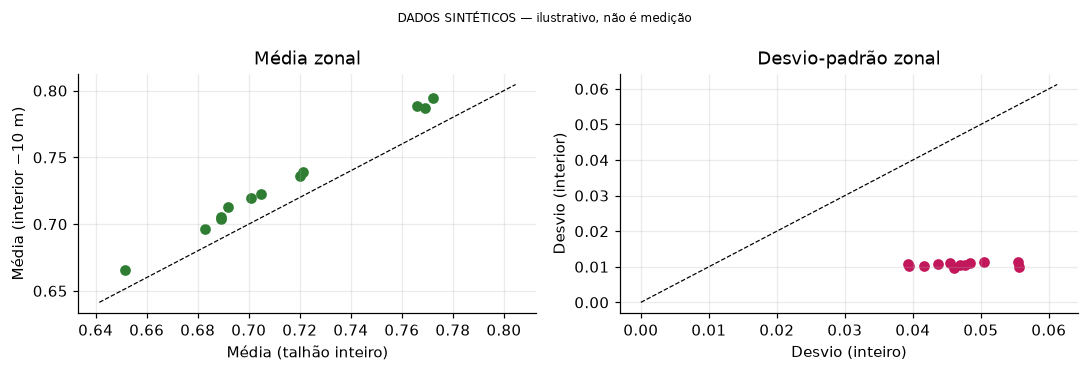

In [5]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.4))
axs[0].scatter(cmp["mean_total"], cmp["mean_interior"], color="#2e7d32")
lim = [cmp[["mean_total", "mean_interior"]].min().min() - .01, cmp[["mean_total", "mean_interior"]].max().max() + .01]
axs[0].plot(lim, lim, "k--", lw=.8); axs[0].set(xlabel="Média (talhão inteiro)", ylabel="Média (interior −10 m)", title="Média zonal")
axs[1].scatter(cmp["std_total"], cmp["std_interior"], color="#c2185b")
lim = [0, cmp[["std_total", "std_interior"]].max().max() * 1.1]
axs[1].plot(lim, lim, "k--", lw=.8); axs[1].set(xlabel="Desvio (inteiro)", ylabel="Desvio (interior)", title="Desvio-padrão zonal")
fig.suptitle(SYNTH_NOTE, fontsize=8); plt.tight_layout()
plt.savefig(OUTPUTS / "figures" / "03_efeito_borda.png"); plt.show()

**Como ler:** pontos acima da diagonal = valor maior no interior. A média *aumenta* um pouco (borda diluída pelo entorno de NDVI baixo) e o desvio *diminui* (menos mistura) — comportamento esperado do filtro aplicado no raster sintético. Em dados reais, o mesmo teste informa o quanto a borda pesa nos seus talhões; **o tamanho do efeito depende do talhão e da imagem**.

## 4. Resumo temporal por talhão

Usando a série (sintética), resumimos cada talhão: nº de observações válidas, % de lacunas, média, desvio, CV e P10/P90.

In [6]:
resumo = zonal.summarize_by_talhao(serie, "ndvi")
rank = zonal.rank_talhoes(resumo, "media")
rank.round(3)

,talhao_id,n_total,n_validas,pct_lacuna,media,desvio,mediana,p10,p90,cv,rank
0,T09,293,195,33.447,0.788,0.031,0.787,0.750,0.828,0.039,1
1,T01,293,184,37.201,0.768,0.028,0.763,0.737,0.810,0.036,2
2,T04,293,171,41.638,0.757,0.029,0.753,0.724,0.795,0.038,3
3,T12,293,193,34.130,0.755,0.029,0.753,0.717,0.794,0.038,4
4,T06,293,188,35.836,0.744,0.028,0.741,0.709,0.782,0.037,5
5,T02,293,181,38.225,0.702,0.029,0.696,0.668,0.743,0.042,6
6,T10,293,182,37.884,0.700,0.027,0.701,0.668,0.737,0.038,7
7,T05,293,183,37.543,0.690,0.028,0.687,0.653,0.728,0.040,8
8,T11,293,196,33.106,0.678,0.031,0.675,0.638,0.718,0.046,9
9,T07,293,198,32.423,0.677,0.028,0.676,0.643,0.715,0.042,10


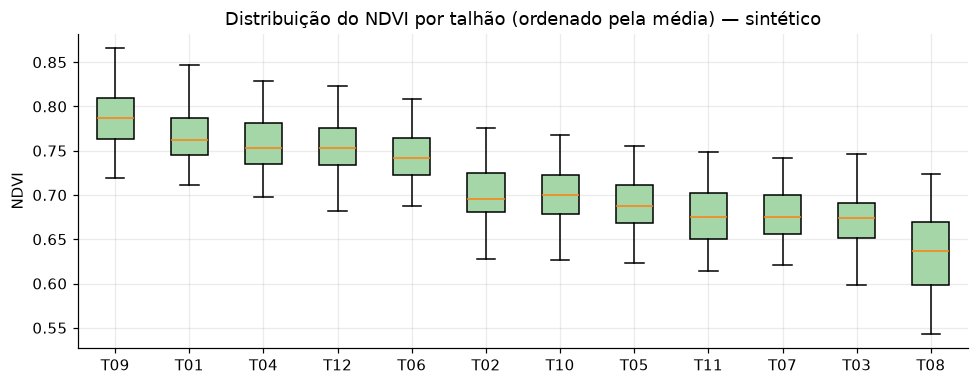

Kruskal-Wallis: H=1582.0, p=0.00e+00 (12 talhões)


In [7]:
ordem = rank["talhao_id"].tolist()
dados = [serie.loc[serie.talhao_id == t, "ndvi"].dropna().values for t in ordem]
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.boxplot(dados, showfliers=False, patch_artist=True, boxprops=dict(facecolor="#a5d6a7"))
ax.set_xticks(range(1, len(ordem) + 1)); ax.set_xticklabels(ordem)
ax.set(ylabel="NDVI", title="Distribuição do NDVI por talhão (ordenado pela média) — sintético")
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "03_boxplot_talhoes.png"); plt.show()
kw = zonal.compare_groups(serie, "ndvi")
print(f"Kruskal-Wallis: H={kw['H']:.1f}, p={kw['p_value']:.2e} ({kw['n_groups']} talhões)")

**Como ler o boxplot:** caixa = quartis (Q1–Q3), linha = mediana, bigodes = amplitude sem outliers. Caixas deslocadas indicam níveis médios diferentes.

**Sobre o teste:** o Kruskal-Wallis compara distribuições entre grupos, mas as observações de um mesmo talhão são **autocorrelacionadas no tempo**, então o p-valor está inflado (parece significativo demais). Use-o só como indicador exploratório; a pergunta agronômica relevante é "a diferença é grande o bastante para importar?" (tamanho de efeito), não "p < 0,05".

## 5. Mapa de calor talhão × mês

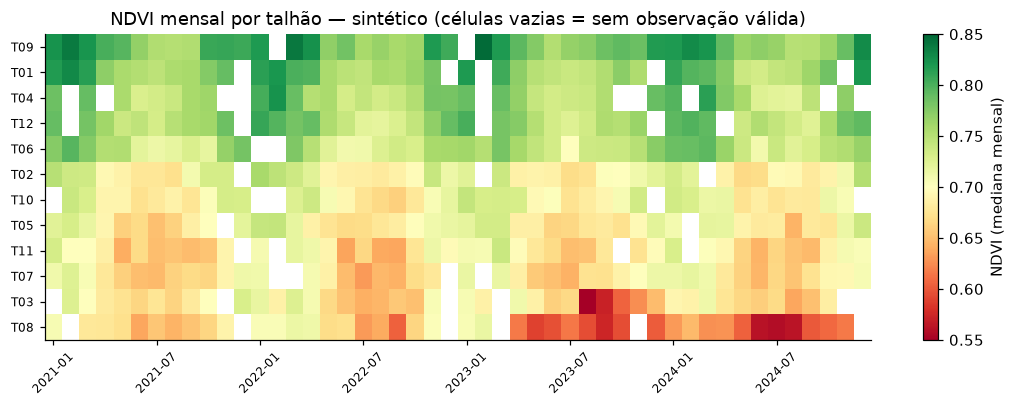

In [8]:
m = ts_lib.monthly_composite(serie, "ndvi", "median", min_obs=2)
piv = m.pivot(index="talhao_id", columns="mes", values="ndvi").loc[ordem]
fig, ax = plt.subplots(figsize=(10, 3.8))
im = ax.imshow(piv.values, aspect="auto", cmap="RdYlGn", vmin=0.55, vmax=0.85)
ax.set_yticks(range(len(piv))); ax.set_yticklabels(piv.index, fontsize=8)
ticks = np.arange(0, piv.shape[1], 6); ax.set_xticks(ticks); ax.set_xticklabels([piv.columns[i].strftime("%Y-%m") for i in ticks], rotation=45, fontsize=8)
ax.grid(False); plt.colorbar(im, label="NDVI (mediana mensal)")
ax.set_title("NDVI mensal por talhão — sintético (células vazias = sem observação válida)")
plt.tight_layout(); plt.savefig(OUTPUTS / "figures" / "03_heatmap_talhao_mes.png"); plt.show()

**Como ler:** cada linha é um talhão, cada coluna um mês; verde = NDVI alto, vermelho = baixo, branco = sem dado. Padrões verticais (todas as linhas mudam juntas) são **sazonalidade/clima/atmosfera**; padrões horizontais (uma linha se destaca) são **diferenças específicas do talhão** — o foco do notebook 04.

In [9]:
saida = tal[["talhao_id", "cultivar", "ano_plantio", "area_ha"]].merge(resumo, on="talhao_id").merge(
    z_int[["talhao_id", "mean", "std"]].rename(columns={"mean": "raster_ndvi_medio_interior", "std": "raster_ndvi_desvio_interior"}), on="talhao_id")
(config.DATA_PROCESSED).mkdir(parents=True, exist_ok=True)
saida.to_csv(config.DATA_PROCESSED / "estatisticas_talhoes.csv", index=False)
print("Salvo em data/processed/estatisticas_talhoes.csv", saida.shape)

Salvo em data/processed/estatisticas_talhoes.csv (12, 15)
